In [55]:
#This cell imports the required libraries for data analysis, visualization, model training, and evaluation.

import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [56]:
#This cell loads the customer dataset into a Pandas DataFrame and displays the first five rows.
import pandas as pd

df = pd.read_csv("customer_purchase_data.csv")

print(df.head())
print(df.columns)
print(df.shape)

   Age  Gender   AnnualIncome  NumberOfPurchases  ProductCategory  \
0   40       1   66120.267939                  8                0   
1   20       1   23579.773583                  4                2   
2   27       1  127821.306432                 11                2   
3   24       1  137798.623120                 19                3   
4   31       1   99300.964220                 19                1   

   TimeSpentOnWebsite  LoyaltyProgram  DiscountsAvailed  PurchaseStatus  
0           30.568601               0                 5               1  
1           38.240097               0                 5               0  
2           31.633212               1                 0               1  
3           46.167059               0                 4               1  
4           19.823592               0                 0               1  
Index(['Age', 'Gender', 'AnnualIncome', 'NumberOfPurchases', 'ProductCategory',
       'TimeSpentOnWebsite', 'LoyaltyProgram', 'DiscountsAvai

In [57]:
#This cell checks the dataset structure, column names, data types, and number of rows and columns.
#This cell identifies missing values and duplicate records in the dataset.
print(df.info())
print(df.isnull().sum())
print("Duplicate rows:", df.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Age                 1500 non-null   int64  
 1   Gender              1500 non-null   int64  
 2   AnnualIncome        1500 non-null   float64
 3   NumberOfPurchases   1500 non-null   int64  
 4   ProductCategory     1500 non-null   int64  
 5   TimeSpentOnWebsite  1500 non-null   float64
 6   LoyaltyProgram      1500 non-null   int64  
 7   DiscountsAvailed    1500 non-null   int64  
 8   PurchaseStatus      1500 non-null   int64  
dtypes: float64(2), int64(7)
memory usage: 105.6 KB
None
Age                   0
Gender                0
AnnualIncome          0
NumberOfPurchases     0
ProductCategory       0
TimeSpentOnWebsite    0
LoyaltyProgram        0
DiscountsAvailed      0
PurchaseStatus        0
dtype: int64
Duplicate rows: 112


In [58]:
#This cell removes exact duplicate rows and checks the dataset shape after duplicate removal.
df = df.drop_duplicates()

print("Dataset shape after removing duplicates:", df.shape)
print("Remaining duplicates:", df.duplicated().sum())

Dataset shape after removing duplicates: (1388, 9)
Remaining duplicates: 0


In [59]:
#This cell counts purchase and non-purchase records and visualizes their distribution.
print(df["PurchaseStatus"].value_counts())

print("\nPercentage:")
print(df["PurchaseStatus"].value_counts(normalize=True) * 100)

PurchaseStatus
0    740
1    648
Name: count, dtype: int64

Percentage:
PurchaseStatus
0    53.314121
1    46.685879
Name: proportion, dtype: float64


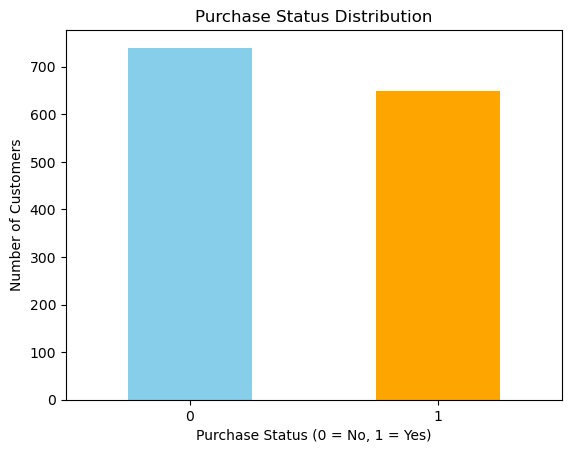

In [60]:

import matplotlib.pyplot as plt

df["PurchaseStatus"].value_counts().sort_index().plot(
    kind="bar",
    color=["skyblue", "orange"]
)

plt.title("Purchase Status Distribution")
plt.xlabel("Purchase Status (0 = No, 1 = Yes)")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.show()

In [61]:
#This cell separates the customer input features (X) from the target variable, PurchaseStatus (y).
X = df.drop("PurchaseStatus", axis=1)
y = df["PurchaseStatus"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (1388, 8)
Target shape: (1388,)


In [62]:
#This cell splits the dataset into training and testing sets to train and evaluate the models.
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (1110, 8)
Testing data: (278, 8)


In [63]:
#This cell standardizes the input features for Logistic Regression using statistics learned from the training data.

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training data scaled:", X_train_scaled.shape)
print("Testing data scaled:", X_test_scaled.shape)

Training data scaled: (1110, 8)
Testing data scaled: (278, 8)


In [64]:
#This cell trains a Logistic Regression model using the scaled training data.

from sklearn.linear_model import LogisticRegression

model = LogisticRegression(random_state=42)

model.fit(X_train_scaled, y_train)

print("Model training completed!")

Model training completed!


In [65]:
#This cell predicts purchase status for the test data and evaluates the model using accuracy, a confusion matrix, and a classification report.
y_pred = model.predict(X_test_scaled)

print("Actual values:")
print(y_test.head(10).values)

print("Predicted values:")
print(y_pred[:10])

Actual values:
[1 0 0 1 1 1 0 1 0 1]
Predicted values:
[1 0 1 1 0 0 0 1 0 1]


In [66]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

Model Accuracy: 83.09 %


In [67]:
from sklearn.metrics import confusion_matrix, classification_report

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Confusion Matrix:
[[124  24]
 [ 23 107]]

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.84      0.84       148
           1       0.82      0.82      0.82       130

    accuracy                           0.83       278
   macro avg       0.83      0.83      0.83       278
weighted avg       0.83      0.83      0.83       278



In [68]:
#This cell trains a Decision Tree classifier to predict customer purchase status using the training data.

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report

dt_model = DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)

dt_model.fit(X_train, y_train)

dt_pred = dt_model.predict(X_test)

dt_accuracy = accuracy_score(y_test, dt_pred)

print("Decision Tree Accuracy:", round(dt_accuracy * 100, 2), "%")
print("\nClassification Report:")
print(classification_report(y_test, dt_pred))

Decision Tree Accuracy: 85.25 %

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.83      0.86       148
           1       0.82      0.88      0.85       130

    accuracy                           0.85       278
   macro avg       0.85      0.85      0.85       278
weighted avg       0.85      0.85      0.85       278



In [69]:
#This cell compares the accuracy of Logistic Regression and Decision Tree on the same test dataset.

print("Logistic Regression:",
      round(accuracy_score(y_test, y_pred) * 100, 2), "%")

print("Decision Tree:",
      round(accuracy_score(y_test, dt_pred) * 100, 2), "%")

Logistic Regression: 83.09 %
Decision Tree: 85.25 %


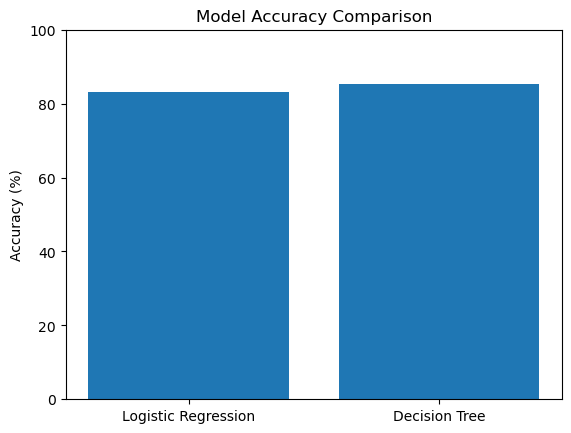

In [70]:
import matplotlib.pyplot as plt

models = ["Logistic Regression", "Decision Tree"]

accuracies = [
    accuracy_score(y_test, y_pred) * 100,
    accuracy_score(y_test, dt_pred) * 100
]

plt.bar(models, accuracies)
plt.ylabel("Accuracy (%)")
plt.title("Model Accuracy Comparison")
plt.ylim(0, 100)
plt.show()

In [71]:
#This cell evaluates the Decision Tree model using its confusion matrix, precision, recall, and F1-score.

from sklearn.metrics import confusion_matrix, classification_report

print("Decision Tree Confusion Matrix:")
print(confusion_matrix(y_test, dt_pred))

print("\nDecision Tree Classification Report:")
print(classification_report(y_test, dt_pred))

Decision Tree Confusion Matrix:
[[123  25]
 [ 16 114]]

Decision Tree Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.83      0.86       148
           1       0.82      0.88      0.85       130

    accuracy                           0.85       278
   macro avg       0.85      0.85      0.85       278
weighted avg       0.85      0.85      0.85       278



In [72]:
#This cell uses the trained Decision Tree model to predict the purchase status of a sample customer.

new_customer = pd.DataFrame([{
    "Age": 30,
    "Gender": 1,
    "AnnualIncome": 75000,
    "NumberOfPurchases": 8,
    "ProductCategory": 2,
    "TimeSpentOnWebsite": 35.0,
    "LoyaltyProgram": 1,
    "DiscountsAvailed": 2
}])

prediction = dt_model.predict(new_customer)[0]

if prediction == 1:
    print("Prediction: Customer may purchase.")
else:
    print("Prediction: Customer may not purchase.")

Prediction: Customer may purchase.
